# **Árbol de decisión**

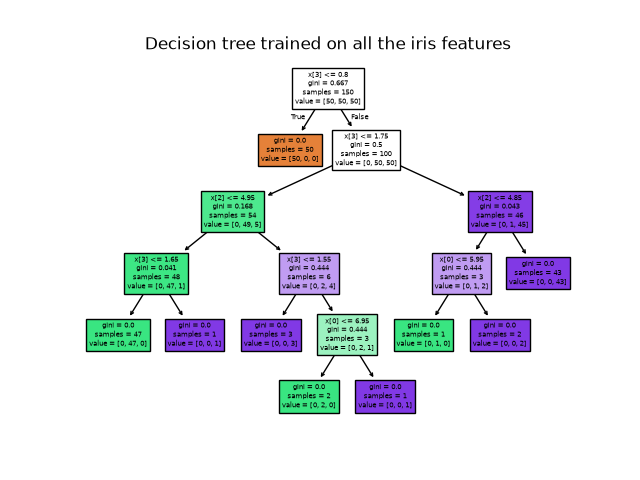

Un árbol de decisión es un modelo que aprende de los datos qué preguntas hacer sobre las variables y dónde cortar, hasta llegar a una predicción del target. Sirve para clasificación y regresión. A diferencia de la regresión lineal, que combina todas las variables a la vez en una sola fórmula, el árbol usa una variable por vez y va dividiendo los datos en grupos.

**Partes de un árbol de decisión **

| Parte | Qué es | Ejemplo (árbol de churn, diapo 3) |
|---|---|---|
| **Nodo raíz** (*root node*) | La primera pregunta. Ahí están **todos** los datos, antes de cualquier división | `Ingreso` |
| **Nodo interno o de decisión** (*internal / decision node*) | Una pregunta intermedia sobre una variable. La respuesta define por dónde se sigue | `Sexo`, `Edad`, `Est.Civil`, `Antigüedad` |
| **Rama** (*branch*) | Una respuesta posible, que conecta un nodo con el siguiente | `>50K`, `<=50K`, `M`, `F` |
| **Hoja o nodo terminal** (*leaf / terminal node*) | El final del camino: no se divide más y da la predicción (una clase o un número) | `Churn=0`, `Churn=1` |

**Idea clave:** un nodo es una pregunta y también **un grupo de datos**. Al bajar por el árbol, el grupo se achica, porque en cada rama quedan solo los casos que dieron esa respuesta.

**Cada camino hasta una hoja es una regla.** Ejemplo: si ingreso >50K y sexo = F y estado civil = soltero, entonces churn = 1.

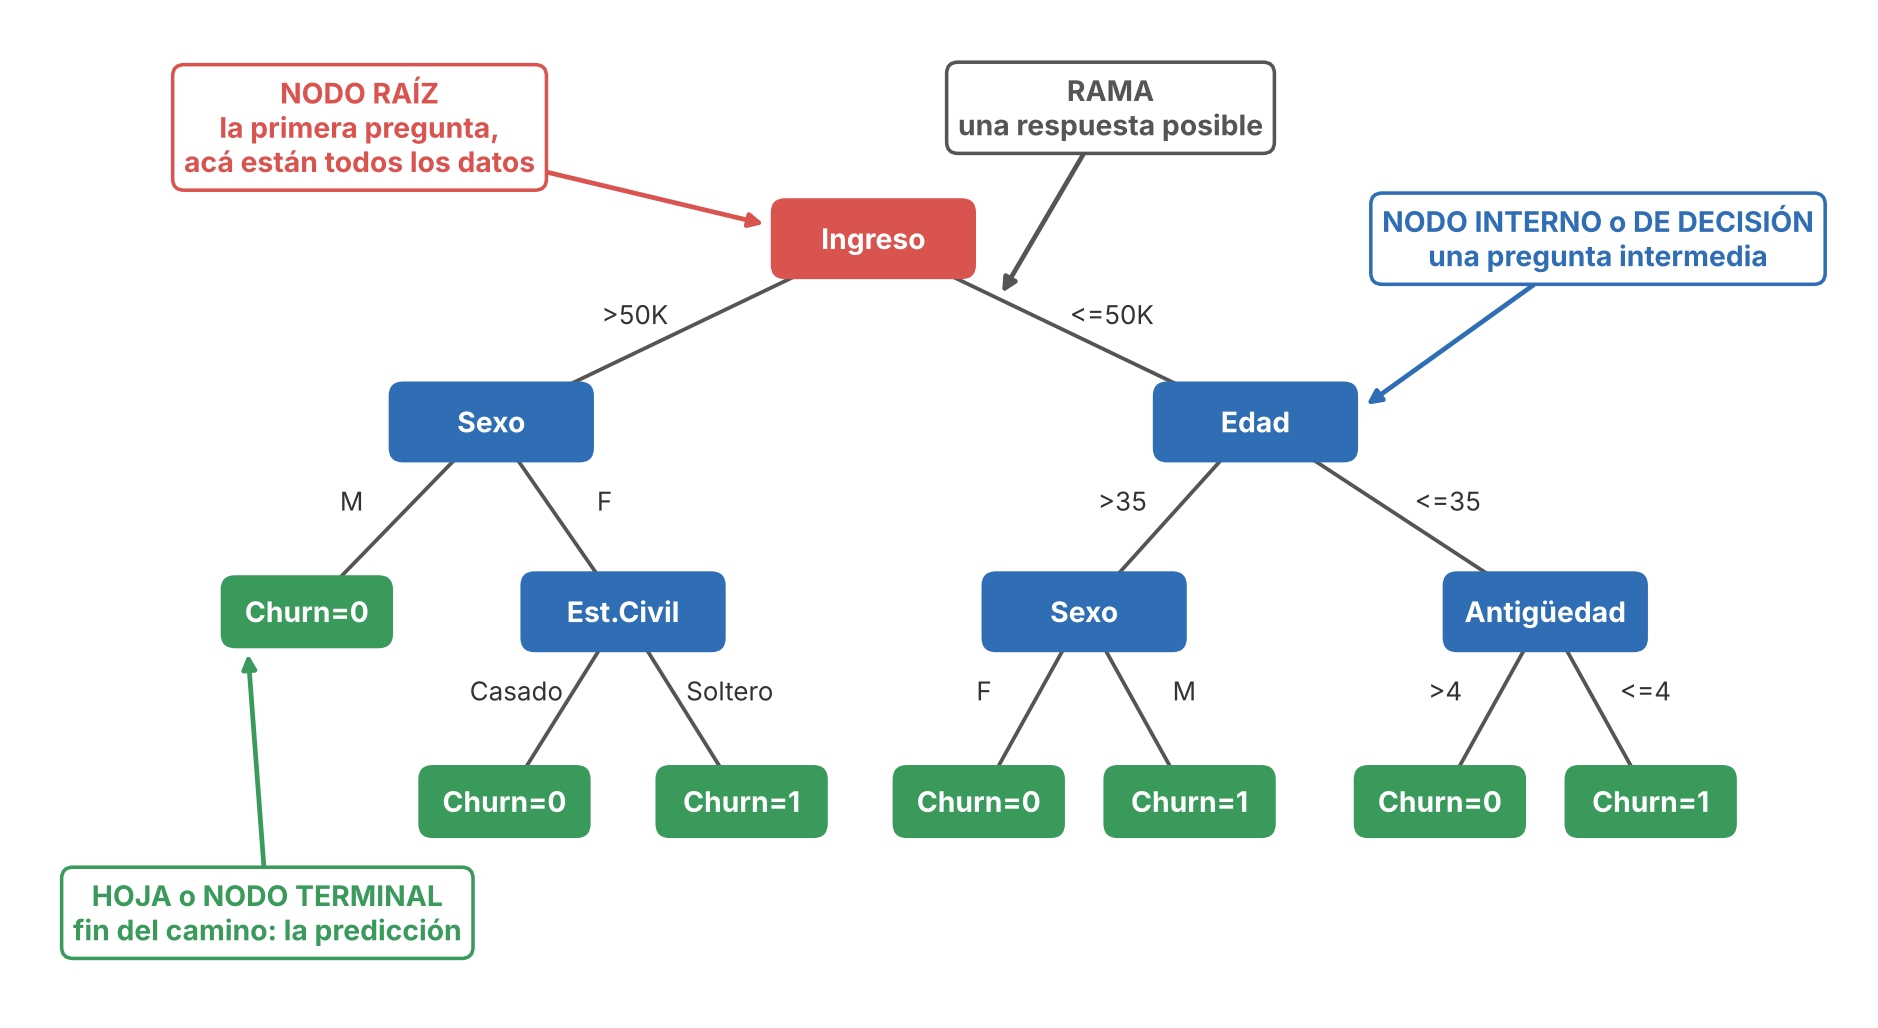

- Arranca con todos los datos en el nodo raíz.
- Busca la mejor pregunta y los divide en subconjuntos.
- Repite el paso 2 dentro de cada subconjunto, como si fuera un problema nuevo y más chico.
- Se detiene cuando se cumple un criterio de parada. Por ejemplo es que todos los datos del nodo sean de la misma clase o que se haya cumplido un hiperparámetro.

**El árbol es greedy (codicioso)**: en cada nodo elige la variable y el corte que mejor funcionan en ese momento, sin mirar si eso lleva al mejor árbol completo, y no vuelve atrás. Por eso puede no llegar al mejor árbol global.

**Pureza:** Ya sabemos que el árbol elige “la mejor pregunta”. Ahora falta ver cómo mide cuál es la mejor, y para eso usa la pureza. La idea: un nodo es puro si todos sus casos son de la misma clase, y mezclado si hay casos de varias clases.

**Impureza de Gini**

**Para qué sirve:** mide qué tan mezclado está un nodo.
- Gini = 0: nodo puro, todos los casos son de la misma clase.
- Cuanto más alto es Gini, más mezclado está el nodo. Con dos clases, el máximo es 0,5 (mezcla 50-50).

**Qué significa:** si saco dos casos al azar de un nodo (con reposición), Gini es la probabilidad de que sean de clases distintas.

**Analogía:** cada nodo es una caja de bolitas, y cada color es una clase. El nodo `Sunny` del dataset de golf tiene 60% Sí (rojas) y 40% No (azules). Un intento consiste en sacar una bolita, anotar el color, devolverla, sacar otra y anotar el color. Si repito el intento 100 veces, en promedio:

| Resultado del intento | Veces de 100 |
|---|---|
| Roja y roja | 36 |
| Azul y azul | 16 |
| Roja y azul | 24 |
| Azul y roja | 24 |

Salen iguales 52 veces y distintas 48 veces, entonces Gini(`Sunny`) = 0,48.

**Fórmula:**

$$Gini(t) = 1 - \sum_{c \in C} p_{t,c}^2$$

| Pedacito | Qué es | En `Sunny` |
|---|---|---|
| $t$ | El nodo que estoy mirando | `Sunny` |
| $c \in C$ | Cada una de las clases | Sí, No |
| $p_{t,c}$ | Proporción de la clase c en el nodo t | 0,60 y 0,40 |
| $p_{t,c}^2$ | Probabilidad de sacar dos casos de esa clase | 0,36 y 0,16 |
| $\sum_{c \in C} p_{t,c}^2$ | Probabilidad de sacar dos casos iguales | 0,52 |
| $1 - \sum_{c \in C} p_{t,c}^2$ | Probabilidad de sacar dos casos distintos: Gini | 0,48 |

**Se lee:** para cada clase, calculá la probabilidad de sacar dos casos de esa clase; sumalas para obtener la probabilidad de que salgan iguales; y restale eso a 1 para obtener la probabilidad de que salgan distintos.

**Aclaración:** los nodos no son el juego. `Sunny` es el grupo de datos (la caja), el juego es la forma de medir la mezcla y Gini es el resultado.



**Cómo separa un árbol de decisión los datos**

**Idea general:** el árbol decide qué preguntar ensayando todas las preguntas posibles y quedándose con la que mejor separa. Una "pregunta" es una variable y un punto de corte, por ejemplo `¿Years < 4.5?`. Con una variable categórica, los grupos salen de sus categorías.

**Proceso en cada nodo:**
1. Ensaya un corte posible, sin dividir todavía.
2. Calcula el Gini de cada grupo que quedaría.
3. Resume esos Gini en un promedio ponderado por la cantidad de casos de cada grupo.
4. Repite con todos los cortes posibles.
5. Elige el corte con **menor** Gini promedio y recién ahí divide.
6. Repite todo dentro de cada grupo nuevo, usando solo sus datos (segmentación recursiva).
7. Se detiene al cumplir un criterio de parada, por ejemplo cuando un nodo es puro (Gini = 0). Ese nodo es una hoja.

**Ejemplo: dataset de golf, primer corte con los 14 días** (Gini antes de cortar: 0,46)

| Pregunta que ensaya | Grupos (Sí / No) | Gini promedio |
|---|---|---|
| **Outlook** | Sunny 3/2 · Overcast 4/0 · Rainy 2/3 | **0,34 (gana)** |
| Humidity | High 3/4 · Normal 6/1 | 0,37 |
| Windy | TRUE 3/3 · FALSE 6/2 | 0,43 |
| Temperature | Hot 2/2 · Mild 4/2 · Cool 3/1 | 0,44 |

**Qué pasa con cada grupo:**

| Grupo | Sí / No | Gini | Qué hace el árbol |
|---|---|---|---|
| Overcast | 4 / 0 | 0 | Ya es puro: hoja, predice Yes |
| Sunny | 3 / 2 | 0,48 | Sigue mezclado: ensaya de nuevo solo con esos 5 días y elige Windy (Gini promedio 0) |
| Rainy | 2 / 3 | 0,48 | Sigue mezclado: ensaya de nuevo solo con esos 5 días y elige Humidity (Gini promedio 0) |

**Árbol final:**

    Outlook
    ├─ Overcast → Yes
    ├─ Sunny → Windy
    │           ├─ TRUE  → No
    │           └─ FALSE → Yes
    └─ Rainy → Humidity
                ├─ High   → No
                └─ Normal → Yes

**Para recordar:**
- Menor Gini promedio significa grupos menos mezclados, o sea más homogéneos.
- Es un proceso *greedy*: elige el mejor corte en ese momento y no vuelve atrás, por lo que puede no llegar al mejor árbol global.
- Dentro de Sunny no se vuelve a ensayar `Outlook` porque todos los casos tienen el mismo valor y la pregunta no separaría nada.
- Una variable numérica sí puede reaparecer más abajo con otro punto de corte.

**Entropía:** La entropía hace el mismo trabajo que Gini: medir qué tan mezclado está un nodo. Cambia la manera de medirlo. Gini usa dos sacadas, y la entropía se pregunta qué tan sorprendido quedás al sacar una bolita.

**Entropía**

**Para qué sirve:** igual que Gini, mide qué tan mezclado está un nodo. Vale 0 si el nodo es puro. Con dos clases, el máximo es 1 (mezcla 50-50).

**Qué significa:** es la **sorpresa promedio** al sacar un caso al azar del nodo. Una clase común sorprende poco y una clase rara sorprende mucho.

**Sorpresa de una clase:** se calcula como $-\log_2 p_k$. Cuando la proporción baja, la sorpresa sube.

| Proporción de la clase | Sorpresa |
|---|---|
| 1 (100%) | 0 |
| 0,60 | 0,74 |
| 0,50 | 1 |
| 0,40 | 1,32 |
| 0,25 | 2 |

**Fórmula:**

$$Entrop\acute{\imath}a = -\sum_k p_k \log_2 p_k$$

| Pedacito | Qué es | En `Sunny` (60% Sí, 40% No) |
|---|---|---|
| $k$ | Cada una de las clases | Sí, No |
| $p_k$ | Proporción de la clase k: qué tan seguido sale | 0,60 y 0,40 |
| $-\log_2 p_k$ | Cuánto sorprende cuando sale | 0,74 y 1,32 |
| $-p_k \log_2 p_k$ | Aporte de esa clase al promedio | 0,44 y 0,53 |
| $-\sum_k p_k \log_2 p_k$ | Sorpresa promedio del nodo: la entropía | 0,97 |

**Se lee:** para cada clase, multiplicá qué tan seguido sale por cuánto sorprende, y sumá todo.

**Por qué se multiplica por la proporción:** porque es un promedio. Cada sorpresa pesa según qué tan seguido ocurre.

**Comparación con Gini (dos clases):**

| Nodo | Gini | Entropía |
|---|---|---|
| Puro | 0 | 0 |
| `Sunny` (60-40) | 0,48 | 0,97 |
| Mezcla 50-50 | 0,50 | 1 |

Las dos miden lo mismo con distinta escala: mezcla. Un valor más bajo significa un nodo más puro.

**Nota de notación:** la diapo escribe $p_{t,c}$ en Gini y $p_k$ en entropía. Las dos son la proporción de una clase dentro del nodo.

**Ganancia de información**

**Qué es:** mide cuánta mezcla sacó una pregunta. Compara la entropía del nodo antes de cortar con la que queda después. El árbol elige el corte con **mayor** ganancia, es decir, la división más informativa.

**Fórmula** (la diapo la define en palabras; esta escritura es un agregado):

$$Ganancia = Entrop\acute{\imath}a_{\text{padre}} - \text{promedio ponderado de } Entrop\acute{\imath}a_{\text{hijos}}$$

**Se lee:** cuánta mezcla había antes, menos cuánta queda después. El promedio se pondera por la cantidad de casos de cada nodo hijo.

**Ejemplo: primer corte del dataset de golf** (entropía antes de cortar: 0,94)

| Pregunta que ensaya | Entropía promedio de los hijos | Ganancia |
|---|---|---|
| **Outlook** | 0,69 | **0,25 (gana)** |
| Humidity | 0,79 | 0,15 |
| Windy | 0,89 | 0,05 |
| Temperature | 0,91 | 0,03 |

**Comparación entre criterios:**

| Criterio | Qué mira | Elige |
|---|---|---|
| Gini | Cuánta mezcla **queda** | El más **bajo** |
| Ganancia de información | Cuánta mezcla **se sacó** | El más **alto** |

No se contradicen: una ganancia alta significa que queda poca mezcla. Los dos buscan grupos más puros. En el golf, los dos eligen `Outlook` como primera pregunta.

**Reducción de la varianza: árboles de regresión**

**Por qué no sirve Gini:** con un target numérico, casi todos los valores son distintos. Gini solo cuenta categorías y no ve si dos números están cerca o lejos.

**Idea:** en regresión, un grupo es homogéneo cuando sus valores se parecen entre sí, es decir, cuando están cerca de su promedio.

| Grupo (ejemplo inventado) | Salarios | Promedio | Varianza | ¿Es buen grupo? |
|---|---|---|---|---|
| A | 480, 500, 520 | 500 | 267 | Sí: predecir 500 representa bien a todos |
| B | 100, 500, 900 | 500 | 106.667 | No: predecir 500 le erra mucho a 100 y a 900 |

**Fórmula** (la diapo la explica en palabras; esta escritura es un agregado):

$$Varianza = \frac{1}{n}\sum_{i=1}^{n}(y_i - \bar{y})^2$$

| Pedacito | Qué es | Se lee |
|---|---|---|
| $y_i$ | El valor real de un caso | El salario de este jugador |
| $\bar{y}$ | El promedio del nodo | Lo que predice el nodo |
| $(y_i - \bar{y})^2$ | La distancia al promedio, al cuadrado | Cuánto se equivoca con este caso |
| $\frac{1}{n}\sum$ | Promediar sobre los casos del nodo | El error promedio del nodo |

Equivale al **MSE** usando el promedio del nodo como predicción.

**Proceso en cada nodo:**
1. Ensaya un corte posible.
2. Calcula la varianza de cada grupo que quedaría.
3. Calcula la varianza ponderada por la cantidad de casos de cada grupo.
4. Repite con todos los cortes posibles.
5. Elige el corte con **menor** varianza ponderada.
6. Repite dentro de cada grupo nuevo.

**Predicción:** cada hoja predice el promedio del target de sus casos.

**Equivalencia entre criterios:**

| | Clasificación con Gini | Clasificación con entropía | Regresión |
|---|---|---|---|
| **Tipo de target** | Categoría | Categoría | Número |
| **Qué mide en cada nodo** | Mezcla de clases | Mezcla de clases | Dispersión de los valores |
| **Medida del nodo** | Gini | Entropía | Varianza |
| **Número para comparar cortes** | Gini promedio ponderado | Ganancia de información | Varianza ponderada |
| **Corte elegido** | El más bajo | El más alto | El más bajo |
| **Qué predice la hoja** | La clase | La clase | El promedio |

**Sobreajuste:** si dejás que el árbol siga cortando, sigue armando grupos cada vez más chicos, hasta llegar a casi un caso por hoja.

**Cómo se controla:**

Limitar la profundidad del árbol.
Limitar la cantidad de hojas.
Exigir una cantidad mínima de datos por hoja.
Ajustar el hiperparámetro de regularización.

El overfitting ocurre cuando el árbol crece tanto que memoriza el train, incluido el ruido: acierta casi todo ahí pero generaliza mal. Más profundidad implica menos sesgo y más varianza del modelo. Se controla limitando la profundidad o la cantidad de hojas, exigiendo un mínimo de casos por hoja y regularizando, con valores elegidos por validación cruzada en el train.

**Hiperparámetros de un árbol en `rpart`**

| Diapo 24 | En `rpart` | Qué controla | Por defecto | Si lo subo, el árbol queda… |
|---|---|---|---|---|
| Profundidad | `maxdepth` | Cuántas preguntas seguidas puede hacer | 30 | Más complejo |
| Cantidad de hojas | No tiene uno directo; se controla con `cp` | Cuántos grupos finales arma | — | — |
| Mínimo de datos por hoja | `minbucket` | Cuántos casos debe tener cada hoja | `minsplit / 3` | Más simple |
| Mínimo para intentar cortar (extra) | `minsplit` | Cuántos casos debe tener un nodo para poder dividirse | 20 | Más simple |
| Regularización | `cp` | Cuánto debe mejorar un corte para que valga la pena | 0,01 | Más simple |
| Criterio (extra) | `parms = list(split = ...)` | Con qué se puntúan los cortes: `"gini"` o `"information"` | `"gini"` | No cambia la complejidad de forma directa |

**Para recordar:**
- `maxdepth` es un permiso: más alto, más libertad para crecer.
- `minbucket`, `minsplit` y `cp` son exigencias: más altos, más difícil cortar.
- Bajar `cp` habilita más cortes, incluso los que mejoran muy poco. El árbol se vuelve más complejo y aumenta el riesgo de sobreajuste.
- Estos valores se eligen con validación cruzada en el train. El test se usa una sola vez, al final.

**Supuestos:** el árbol no pide una distribución de los datos, normalidad ni relación lineal. Esa es la gran diferencia con la regresión lineal, y por eso no se verifican los supuestos de los residuos.

**Para qué es bueno:**

- Es fácil de interpretar y de graficar.
- No necesita estandarizar y requiere poco preprocesamiento.
- Selecciona variables automáticamente y sirve para explorar.
- Puede predecir aunque falte un dato, según la implementación.

## Ingreso de librerías y del dataset

Los datos no se encuentran en el CRAN, pero si en GitHub,
para poder acceder, instalamos primero la librería devtools.

In [6]:
install.packages("remotes")
remotes::install_github("Chicago/RSocrata", ref="dev")
install.packages("tidymodels")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Skipping install of 'RSocrata' from a github remote, the SHA1 (ed42d3bb) has not changed since last install.
  Use `force = TRUE` to force installation

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘shape’, ‘future.apply’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘listenv’, ‘parallelly’, ‘splitfngr’, ‘prodlim’, ‘future’, ‘warp’, ‘mixopt’, ‘numDeriv’, ‘lbfgs’, ‘RcppArmadillo’, ‘DiceDesign’, ‘sfd’, ‘sparsevctrs’, ‘patchwork’, ‘globals’, ‘clock’, ‘gower’, ‘ipred’, ‘timeDate’, ‘furrr’, ‘slider’, ‘GauPro’, ‘modelenv’, ‘dials’, ‘hardhat’, ‘infer’, ‘modeldata’, ‘parsnip’, ‘recipes’, ‘rsample’, ‘tailor’, ‘tune’, ‘workflows’, ‘workflowsets’, ‘yardstick’




En primer lugar vamos a ingresar los datos y las librerias correspondientes.

In [7]:
library(tidyverse)
library(lubridate) # Librería para trabajar con fechas
library(RSocrata) # Librería para acceder a datos desde Socrata Open Data API
library(tidymodels)

── Attaching packages ────────────────────────────────────── tidymodels 1.5.0 ──

✔ broom        1.0.13     ✔ rsample      1.3.2 
✔ dials        1.4.4      ✔ tailor       0.1.0 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ recipes      1.4.0      ✔ yardstick    1.4.0 

── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ scales::discard() masks purrr::discard()
✖ dplyr::filter()   masks stats::filter()
✖ recipes::fixed()  masks stringr::fixed()
✖ dplyr::lag()      masks stats::lag()
✖ yardstick::spec() masks readr::spec()
✖ recipes::step()   masks stats::step()



Datos extraidos de https://juliasilge.com/blog/chicago-traffic-model/

In [9]:
# Calculamos la fecha exacta de hace 2 años desde el día de hoy
years_ago <- today() - years(2)

# Construimos la URL para acceder a los datos de accidentes de tráfico en Chicago
crash_url <- glue::glue("https://data.cityofchicago.org/Transportation/Traffic-Crashes-Crashes/85ca-t3if?$where=CRASH_DATE > '{years_ago}'")

# Intentamos leer los datos aumentando el tiempo límite de conexión y con reintentos
options(timeout = max(300, getOption("timeout")))

message("Iniciando descarga de datos de Chicago Socrata (esto puede demorar unos minutos)...")
success <- FALSE
attempts <- 3

while(!success && attempts > 0) {
  tryCatch({
    crash_raw <- as_tibble(read.socrata(crash_url))
    success <- TRUE
  }, error = function(e) {
    attempts <<- attempts - 1
    message(paste("Error de conexión detectado. Reintentando... Intentos restantes:", attempts))
    if(attempts == 0) stop(e)
    Sys.sleep(5)
  })
}

message("¡Datos descargados con éxito!")

Iniciando descarga de datos de Chicago Socrata (esto puede demorar unos minutos)...

¡Datos descargados con éxito!



## Limpieza de los datos


In [10]:
crash <- crash_raw %>%
  arrange(desc(crash_date)) %>% # Ordenamos los registros en orden descendente
  transmute( # Seleccionamos y transformamos variables con 'transmute'
    injuries = if_else(injuries_total > 0, "injuries", "none"), # Creamos v 'injuries' q indica si hubo  lesiones
    crash_date,     # Conservamos la fecha y hora del accidente
    crash_hour,
    report_type = if_else(report_type == "", "UNKNOWN", report_type), # Establecemos "UNKNOWN" si 'report_type' está vacío
    num_units,  # Seleccionamos varias variables relevantes para el análisis
    posted_speed_limit,
    weather_condition,
    lighting_condition,
    roadway_surface_cond,
    first_crash_type,
    trafficway_type,
    prim_contributory_cause,
    latitude, longitude
  ) %>%
  na.omit() # Eliminamos las filas con valores NA


crash

injuries,crash_date,crash_hour,report_type,num_units,posted_speed_limit,weather_condition,lighting_condition,roadway_surface_cond,first_crash_type,trafficway_type,prim_contributory_cause,latitude,longitude
<chr>,<dttm>,<int>,<chr>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
none,2026-11-09 01:10:00,1,NOT ON SCENE (DESK REPORT),1,30,CLEAR,"DARKNESS, LIGHTED ROAD",DRY,FIXED OBJECT,OTHER,UNABLE TO DETERMINE,41.83839,-87.60812
none,2026-11-09 00:05:00,0,ON SCENE,2,0,CLEAR,"DARKNESS, LIGHTED ROAD",DRY,OTHER OBJECT,OTHER,UNABLE TO DETERMINE,41.99174,-87.67020
none,2026-11-09 00:03:00,0,NOT ON SCENE (DESK REPORT),2,30,UNKNOWN,UNKNOWN,UNKNOWN,TURNING,UNKNOWN,FAILING TO YIELD RIGHT-OF-WAY,41.89019,-87.63240
none,2026-11-08 23:52:00,23,ON SCENE,2,30,CLEAR,"DARKNESS, LIGHTED ROAD",DRY,SIDESWIPE OPPOSITE DIRECTION,NOT DIVIDED,IMPROPER OVERTAKING/PASSING,41.75623,-87.70244
none,2026-11-08 23:20:00,23,ON SCENE,2,40,CLEAR,"DARKNESS, LIGHTED ROAD",DRY,TURNING,T-INTERSECTION,IMPROPER LANE USAGE,41.87332,-87.61746
none,2026-11-08 21:48:00,21,NOT ON SCENE (DESK REPORT),2,30,CLEAR,"DARKNESS, LIGHTED ROAD",DRY,PARKED MOTOR VEHICLE,ONE-WAY,UNABLE TO DETERMINE,41.86074,-87.71267
none,2026-11-08 21:40:00,21,NOT ON SCENE (DESK REPORT),2,30,CLEAR,"DARKNESS, LIGHTED ROAD",DRY,ANGLE,NOT DIVIDED,FAILING TO REDUCE SPEED TO AVOID CRASH,41.88102,-87.64719
injuries,2026-11-08 21:38:00,21,ON SCENE,2,30,CLEAR,"DARKNESS, LIGHTED ROAD",DRY,PEDESTRIAN,CENTER TURN LANE,IMPROPER BACKING,41.91018,-87.68997
none,2026-11-08 21:30:00,21,NOT ON SCENE (DESK REPORT),2,30,UNKNOWN,UNKNOWN,DRY,SIDESWIPE SAME DIRECTION,NOT DIVIDED,FAILING TO YIELD RIGHT-OF-WAY,41.88581,-87.64509


# División de los datos

In [11]:
set.seed(123)
crash_split <- initial_split(crash, strata = injuries, prop=0.75)
crash_train <- training(crash_split)
crash_test <- testing(crash_split)

Esta división es arbitraria, podemos hacer divisiones de 75/25, 80/20, 90/10, etc.

In [12]:
crash_train$injuries <- as.factor(crash_train$injuries)
crash_test$injuries <- as.factor(crash_test$injuries)

# Receta

Con este nombre agrupamos todos los **pre-procesamientos** que vamos a realizar al dataset de *train*, con lo cual haremos el modelado. Estas mismas operaciones se realizan al final en el dataset de *test*.

In [14]:
if (!requireNamespace("themis", quietly = TRUE)) {
  install.packages("themis")
}
library(themis)

# Creamos una receta para el modelo con la variable de respuesta 'injuries' y el resto de variables predictoras en 'crash_train'
crash_rec <- recipe(injuries ~ ., data = crash_train) %>%
  # Convertimos 'injuries' a un factor
  step_mutate(injuries = as.factor(injuries)) %>%
  # Extraemos componentes de fecha a partir de 'crash_date' para convertirla en variables como año, mes, día, etc.
  step_date(crash_date) %>%
  # Eliminamos la columna original 'crash_date' después de extraer sus componentes de fecha
  step_rm(crash_date) %>%
  # Agrupamos niveles menos frecuentes de variables categóricas bajo una nueva categoría llamada "OTHER"
  step_other(
    weather_condition,          # Condición del clima en el momento del accidente
    first_crash_type,           # Tipo inicial del accidente
    trafficway_type,            # Tipo de vía donde ocurrió el accidente
    prim_contributory_cause,    # Causa primaria que contribuyó al accidente
    other = "OTHER"             # Nombre de la categoría "otros" para agrupar niveles raros
  ) %>%
  # Realizamos downsampling en la variable de respuesta 'injuries' para equilibrar las clases en caso de desbalance
  step_downsample(injuries)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘RANN’, ‘ROSE’




Vemos la receta que hemos creado

In [15]:
crash_rec



── Recipe ──────────────────────────────────────────────────────────────────────



── Inputs 

Number of variables by role

outcome:    1
predictor: 13



── Operations 

• Variable mutation for: as.factor(injuries)

• Date features from: crash_date

• Variables removed: crash_date

• Collapsing factor levels for: weather_condition first_crash_type, ...

• Down-sampling based on: injuries



# Modelo

En esta instancia vamos a elegir el modelo para el entrenamiento, tambien seleccionamos de que libreria vamos a tomar las funciones de R y también el tipo de tarea.
En este caso vamos a hacer, un árbol de decisión, de la libreria rpart y una tarea de clasificación.

In [16]:
tree_spec <- decision_tree() %>%
  set_engine("rpart") %>%
  set_mode("classification")
tree_spec

Decision Tree Model Specification (classification)

Computational engine: rpart 


# Workflow

El workflow nos permite trabajar de manera ordenada en MACHINE LEARNING, y es una buena práctica utilizarlo siempre que tengamos más de un paso de pre-procesamiento.

* Agregamos la receta mediante add_recipe(), y luego,
* agregamos el modelo.

Luego imprimo el workflow

In [17]:
crash_wf <- workflow() %>%
  add_recipe(crash_rec) %>%
  add_model(tree_spec)

crash_wf

══ Workflow ════════════════════════════════════════════════════════════════════
Preprocessor: Recipe
Model: decision_tree()

── Preprocessor ────────────────────────────────────────────────────────────────
5 Recipe Steps

• step_mutate()
• step_date()
• step_rm()
• step_other()
• step_downsample()

── Model ───────────────────────────────────────────────────────────────────────
Decision Tree Model Specification (classification)

Computational engine: rpart 


### Error de estimacion del modelo en TRAIN

Esta es la primer etapa de nuestro modelo, vamos entrenarlo en esta etapa, antes SOLO LO DEFINIMOS NO HEMOS CALCULADO NADA.
Con la función fit(), se realiza el entrenamiento en este caso.

Depende de como decidamos modelar los datos, esta función fit(), puede cambiar por otra, por ejemplo, fit_resamples(), si hacemos validación cruzada.

In [18]:
tree_fit <- crash_wf %>%
  fit(data = crash_train)

#imprimo el modelo
tree_fit

══ Workflow [trained] ══════════════════════════════════════════════════════════
Preprocessor: Recipe
Model: decision_tree()

── Preprocessor ────────────────────────────────────────────────────────────────
5 Recipe Steps

• step_mutate()
• step_date()
• step_rm()
• step_other()
• step_downsample()

── Model ───────────────────────────────────────────────────────────────────────
n= 54530 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

1) root 54530 27265 injuries (0.5000000 0.5000000)  
  2) report_type=ON SCENE,UNKNOWN 33538 11421 injuries (0.6594609 0.3405391)  
    4) first_crash_type=ANGLE,REAR END,TURNING,OTHER 25874  6449 injuries (0.7507537 0.2492463) *
    5) first_crash_type=PARKED MOTOR VEHICLE,SIDESWIPE SAME DIRECTION 7664  2692 none (0.3512526 0.6487474) *
  3) report_type=NOT ON SCENE (DESK REPORT) 20992  5148 none (0.2452363 0.7547637) *

## Error en TRAIN

En este paso lo que vamos a hacer es agregar la columna de la predicción a los datos de TRAIN, mediante la función bind_cols.
Esto nos va a permitir ver la diferencia entre la predicción y el valor verdadero.

In [19]:
## Error en TRAIN (Corrección Robusta y Didáctica para step_downsample)

# 1. Aplicamos la RECETA al conjunto de entrenamiento, pero OMITIMOS el paso de MUESTREO (downsample).
# Usamos `bake()` para aplicar las transformaciones (fechas, step_other, etc.)
# sobre el conjunto de TRAIN ORIGINAL.
# Nota: La función `bake()` aplica todas las transformaciones de la receta.
prepared_train_data <- tree_fit %>%
  extract_recipe() %>%
  bake(new_data = crash_train)

In [20]:
# 2. Extraemos el MODELO DE ÁRBOL ya entrenado.
model_fit_only <- tree_fit %>%
  extract_fit_parsnip()

In [21]:
# 3. Generamos las predicciones de CLASE usando el modelo entrenado sobre los datos transformados.
tree_predictions_train <- predict(model_fit_only, new_data = prepared_train_data) %>%
    rename(.pred_tree = .pred_class)

In [22]:
# 4. Unimos las predicciones a los datos originales de entrenamiento.
results_train <- crash_train %>%
    bind_cols(tree_predictions_train)
  results_train

injuries,crash_date,crash_hour,report_type,num_units,posted_speed_limit,weather_condition,lighting_condition,roadway_surface_cond,first_crash_type,trafficway_type,prim_contributory_cause,latitude,longitude,.pred_tree
<fct>,<dttm>,<int>,<chr>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<fct>
injuries,2026-11-08 21:38:00,21,ON SCENE,2,30,CLEAR,"DARKNESS, LIGHTED ROAD",DRY,PEDESTRIAN,CENTER TURN LANE,IMPROPER BACKING,41.91018,-87.68997,injuries
injuries,2026-11-08 18:00:00,18,ON SCENE,2,30,CLEAR,"DARKNESS, LIGHTED ROAD",DRY,ANGLE,NOT DIVIDED,FAILING TO YIELD RIGHT-OF-WAY,41.94675,-87.70628,injuries
injuries,2026-11-08 17:30:00,17,ON SCENE,1,30,CLEAR,DUSK,DRY,FIXED OBJECT,DIVIDED - W/MEDIAN BARRIER,UNABLE TO DETERMINE,41.74873,-87.66326,injuries
injuries,2026-11-08 17:25:00,17,ON SCENE,3,30,CLEAR,"DARKNESS, LIGHTED ROAD",DRY,REAR END,T-INTERSECTION,UNDER THE INFLUENCE OF ALCOHOL/DRUGS (USE WHEN ARREST IS EFFECTED),41.84641,-87.67554,injuries
injuries,2026-11-08 17:19:00,17,ON SCENE,3,35,CLEAR,"DARKNESS, LIGHTED ROAD",DRY,ANGLE,DIVIDED - W/MEDIAN (NOT RAISED),DISREGARDING TRAFFIC SIGNALS,41.87315,-87.62045,injuries
injuries,2026-11-08 16:50:00,16,NOT ON SCENE (DESK REPORT),2,30,CLEAR,UNKNOWN,UNKNOWN,PEDESTRIAN,NOT DIVIDED,FAILING TO YIELD RIGHT-OF-WAY,41.99778,-87.69323,none
injuries,2026-11-08 16:40:00,16,ON SCENE,2,30,CLEAR,DUSK,DRY,PEDESTRIAN,NOT DIVIDED,FAILING TO YIELD RIGHT-OF-WAY,41.86682,-87.66653,injuries
injuries,2026-11-08 16:21:00,16,ON SCENE,2,30,CLEAR,DAYLIGHT,DRY,PEDESTRIAN,NOT DIVIDED,DISTRACTION - FROM INSIDE VEHICLE,41.79136,-87.64615,injuries
injuries,2026-11-08 16:08:00,16,ON SCENE,3,30,CLEAR,DUSK,DRY,REAR END,NOT DIVIDED,UNABLE TO DETERMINE,41.90274,-87.74613,injuries


In [23]:
# 5. Vemos las métricas de TRAIN
metrics(results_train, truth = injuries, estimate = .pred_tree)

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
accuracy,binary,0.7554142
kap,binary,0.3519068


### Error de estimacion del modelo en TEST

Esta etapa es la predicción del modelo de ML, y es el resultado que generalmente se reporta.
IMPORTANTE: los resultados se deben reportar SI O SI, puede o no ir acompañado de los resultados de TRAIN.

In [24]:
## Error en TEST (Código que funciona)

# 1. Extraemos la receta preparada del workflow ajustado 'tree_fit'.
prepared_recipe <- tree_fit %>%
  extract_recipe()

In [25]:
# 2. Aplicamos la receta preparada a los datos de prueba originales (crash_test).
# La función bake transforma los datos (crea las columnas de fecha, agrupa variables, etc.)
# y, críticamente, omite el paso de muestreo (step_downsample).
baked_test <- prepared_recipe %>%
  bake(new_data = crash_test)

In [26]:
# 3. Extraemos el modelo de árbol de decisión entrenado (objeto rpart crudo).
model_fit_only <- tree_fit %>%
  extract_fit_parsnip()

In [27]:
# 4. Generamos las predicciones de CLASE y PROBABILIDAD.
class_preds <- predict(model_fit_only,
                       new_data = baked_test %>% select(-injuries),
                       type = "class") %>%
  rename(.pred_tree = .pred_class)

In [28]:
# 5. Unimos las predicciones al dataset original de test.
results_test <- bind_cols(class_preds, crash_test)
results_test

.pred_tree,injuries,crash_date,crash_hour,report_type,num_units,posted_speed_limit,weather_condition,lighting_condition,roadway_surface_cond,first_crash_type,trafficway_type,prim_contributory_cause,latitude,longitude
<fct>,<fct>,<dttm>,<int>,<chr>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
injuries,none,2026-11-09 00:05:00,0,ON SCENE,2,0,CLEAR,"DARKNESS, LIGHTED ROAD",DRY,OTHER OBJECT,OTHER,UNABLE TO DETERMINE,41.99174,-87.67020
none,none,2026-11-09 00:03:00,0,NOT ON SCENE (DESK REPORT),2,30,UNKNOWN,UNKNOWN,UNKNOWN,TURNING,UNKNOWN,FAILING TO YIELD RIGHT-OF-WAY,41.89019,-87.63240
none,none,2026-11-08 21:30:00,21,NOT ON SCENE (DESK REPORT),2,30,UNKNOWN,UNKNOWN,DRY,SIDESWIPE SAME DIRECTION,NOT DIVIDED,FAILING TO YIELD RIGHT-OF-WAY,41.88581,-87.64509
injuries,none,2026-11-08 21:21:00,21,ON SCENE,2,25,CLEAR,DARKNESS,UNKNOWN,TURNING,ONE-WAY,DISTRACTION - FROM OUTSIDE VEHICLE,41.87603,-87.70149
none,none,2026-11-08 19:00:00,19,NOT ON SCENE (DESK REPORT),2,25,CLEAR,"DARKNESS, LIGHTED ROAD",UNKNOWN,ANGLE,FOUR WAY,UNABLE TO DETERMINE,41.69770,-87.56089
injuries,none,2026-11-08 18:57:00,18,ON SCENE,2,20,CLEAR,DARKNESS,DRY,TURNING,FOUR WAY,IMPROPER OVERTAKING/PASSING,41.74408,-87.60507
injuries,none,2026-11-08 18:53:00,18,ON SCENE,1,30,CLEAR,"DARKNESS, LIGHTED ROAD",DRY,FIXED OBJECT,NOT DIVIDED,UNABLE TO DETERMINE,41.83446,-87.68398
injuries,none,2026-11-08 18:47:00,18,ON SCENE,2,30,CLEAR,"DARKNESS, LIGHTED ROAD",DRY,REAR END,DIVIDED - W/MEDIAN (NOT RAISED),UNABLE TO DETERMINE,41.87525,-87.62777
none,none,2026-11-08 18:15:00,18,NOT ON SCENE (DESK REPORT),2,30,CLEAR,DARKNESS,DRY,PARKED MOTOR VEHICLE,NOT DIVIDED,DISTRACTION - FROM OUTSIDE VEHICLE,41.87821,-87.67181


In [29]:
# 6. Vemos las métricas de TEST
selected_metrics <- metric_set(accuracy, sensitivity, specificity, precision, f_meas)
selected_metrics(results_test, truth = injuries, estimate = .pred_tree)

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
accuracy,binary,0.7535634
sensitivity,binary,0.7000770
specificity,binary,0.7643156
precision,binary,0.3738763
f_meas,binary,0.4874368


# Matriz de confusión
Vamos a visualizar la matriz de confusión

In [30]:
# Calcular la matriz de confusión
library(yardstick)
conf_matrix <- conf_mat(data = results_test,
                                 truth = injuries,
                                 estimate = .pred_tree)

# Mostrar la matriz de confusión
print(conf_matrix)

          Truth
Prediction injuries  none
  injuries     6363 10656
  none         2726 34557


## Curva ROC

In [31]:
prob_preds <- predict(model_fit_only,
                      new_data = baked_test %>% select(-injuries),
                      type = "prob") %>%
  bind_cols(baked_test %>% select(injuries))

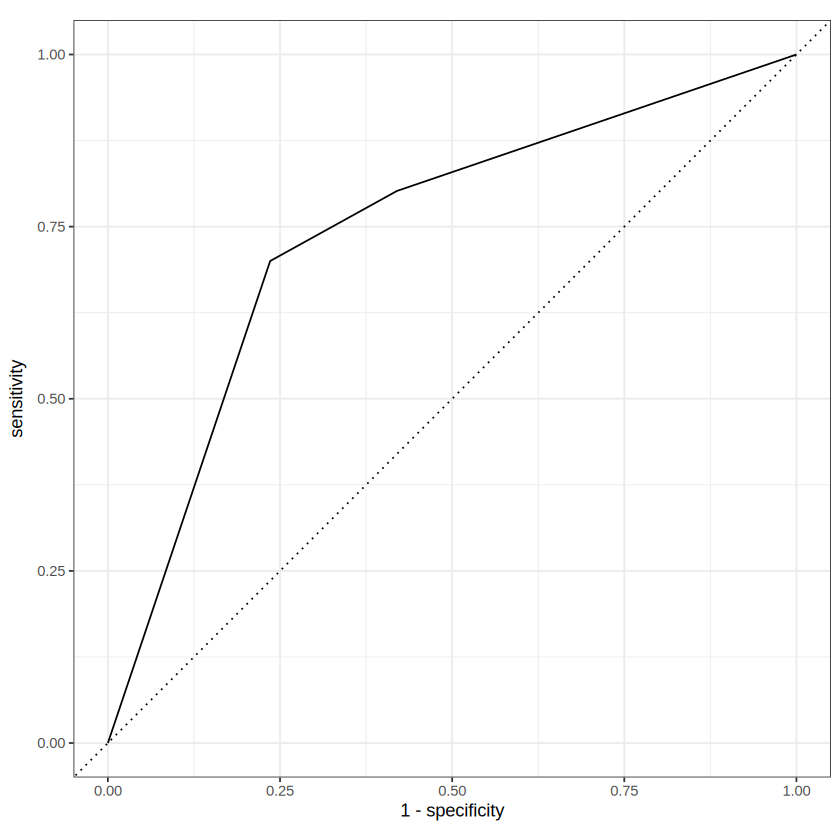

In [32]:
prob_preds %>%
  roc_curve(injuries, .pred_injuries) %>%
  autoplot()